# A6 · LightGBM: let the computer choose the boxes

**Where we are**

```
0 Frame    → predict a SAFE slot (the q-point); q is the PO's setting (0.67 / 0.75 / 0.80)
1 Collect  → simulator made the visits
2 Explore  → found the problems
3 Prepare  → fixed them; split: train Jan–May, valid June, test Jul–Aug; built the 11 feature columns
4 Baseline → best simple method B3: 1.349 on June (q = 0.8); best possible 1.130
5 Train    → HERE: boosting, first by hand, then LightGBM
```

**Words for this lesson**

| Word | Plain meaning |
|---|---|
| tree | a chain of yes/no questions ("is it a follow-up?", "reports ≤ 3?") that sorts visits into boxes |
| leaf | the end of a branch: one box, with one number |
| round | one new small tree added to the model |
| push (gradient) | for each visit, the direction that lowers the score: up by q if it ran late, down by 1 − q if the doctor sat idle |
| learning rate | how big a step each tree takes (0.05 = 5% of the way) |
| overfitting | the model starts memorising individual training visits; the training score keeps improving while June gets worse |
| early stopping | stop adding trees once June stops improving, and keep the best number |

**Before running this notebook,** write the `TODO(you)` parts and make the tests pass:

| File | Your parts | Test |
|---|---|---|
| `slotpred/mini_boost.py` | `pinball_push`, `MiniBoost.fit` | `.venv/Scripts/python.exe -m pytest tests/test_mini_boost.py -v` |
| `slotpred/train_lgbm.py` | `make_model`, `fit_one` | `.venv/Scripts/python.exe -m pytest tests/test_train_lgbm.py -v` |

Everything is fitted on **train** and scored on **June**. The test months stay locked until A8.

In [1]:
%load_ext autoreload
%autoreload 2

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from slotpred.config import OUT, Q_CANDIDATES
from slotpred.features import FEATURES, make_xy
from slotpred.metrics import evaluate, pinball_loss
from slotpred.mini_boost import MiniBoost, to_numeric
from slotpred.prepare import load_prepared
from slotpred.train_lgbm import PARAMS, fit_all, fit_one

splits, state = load_prepared()
X_train, y_train = make_xy(splits["train"], state)     # the 11 booking-time columns from A4
X_valid, y_valid = make_xy(splits["valid"], state)
baselines = pd.read_csv(OUT / "baselines_valid.csv")   # your A5 leaderboard
print(X_train.shape, X_valid.shape)
print(FEATURES)

(24818, 11) (5515, 11)
['department', 'visit_type', 'doctor', 'clinic', 'age', 'age_missing', 'interpreter', 'teleconsult', 'prior_reports', 'weekday', 'hour']


## Part 1 · Boosting by hand (your `MiniBoost`)

q = 0.8, 100 rounds, each tree at most 8 boxes of at least 30 visits, learning rate 0.1. sklearn's trees need numbers, so `to_numeric` turns category columns into codes.

In [2]:
q = 0.8
Xn_train, Xn_valid = to_numeric(X_train), to_numeric(X_valid)
mini = MiniBoost(q, n_rounds=100, learning_rate=0.1, max_leaf_nodes=8, min_samples_leaf=30).fit(Xn_train, y_train)
print("start (the training P80, like B1):", round(mini.start_, 2))
print("training score after rounds 1, 10, 50, 100:", [round(mini.history_[i], 3) for i in (0, 9, 49, 99)])

start (the training P80, like B1): 17.95
training score after rounds 1, 10, 50, 100: [np.float64(2.139), np.float64(1.581), np.float64(1.219), np.float64(1.165)]


{1: np.float64(2.104), 5: np.float64(1.761), 10: np.float64(1.567), 25: np.float64(1.336), 50: np.float64(1.21), 100: np.float64(1.161)}


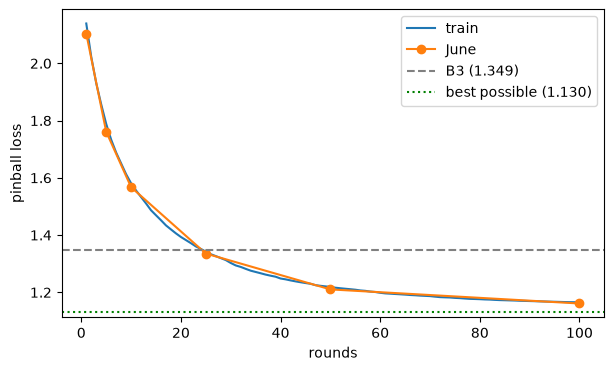

In [ ]:
# TODO(you): the June score after 1, 5, 10, 25, 50 and 100 rounds.
# hint: pinball_loss(y_valid, mini.predict(Xn_valid, n_rounds=n), q)
# Then plot the training history (mini.history_) and your June scores against the number of rounds,
# with horizontal lines for B3 (1.349) and the best possible score (1.130).

rounds = [1, 5, 10, 25, 50, 100]
june = [pinball_loss(y_valid, mini.predict(Xn_valid, n_rounds=n), q) for n in rounds]
print({n: round(s, 3) for n, s in zip(rounds, june)})

plt.figure(figsize=(7, 4))
plt.plot(range(1, len(mini.history_) + 1), mini.history_, label="train")
plt.plot(rounds, june, "o-", label="June")
plt.axhline(1.349, color="gray", ls="--", label="B3 (1.349)")
plt.axhline(1.130, color="green", ls=":", label="best possible (1.130)")
plt.xlabel("rounds"); plt.ylabel("pinball loss"); plt.legend(); plt.show()

In [7]:
print("start:", round(mini.start_, 2))
print("June score at round 0:", pinball_loss(y_valid, mini.predict(Xn_valid, n_rounds=0), q))
print(baselines.query("q == 0.8")[["method", "pinball"]])   # compare with B1

start: 17.95
June score at round 0: 2.244073133877304
                                    method  pinball
10                             B0 fixed 15    2.410
11                           B1 one number    2.244
12              B2 department + visit type    1.404
13  B3 doctor + visit type (backoff to B2)    1.349
14                          Oracle (floor)    1.130


In [8]:
for n in range(20, 26):
    print(n, round(pinball_loss(y_valid, mini.predict(Xn_valid, n_rounds=n), q), 3))

20 1.386
21 1.375
22 1.364
23 1.353
24 1.344
25 1.336


**Questions**
1. Where does round 0 start, and which A5 baseline is that the same as?
2. After how many rounds does your hand-made booster beat B3 on June?
3. How close does it get to the best possible score?

*Answers:*
1.17.95 minutes: this is mini.start_, which your MiniBoost computes from the training data. It is the 80th percentile of the training times. The notebook prints it in cell 3 as "start (the training P80, like B1)".
2.after 24 round
3.about 1.336

## A look inside one tree

Your first round's tree, as readable rules. Category columns appear as codes; `state.categories` (A4) lists them in order, so code 0 of `visit_type` is the first entry.

In [4]:
from sklearn.tree import export_text
first_tree, first_values = mini.rounds_[0]
print(export_text(first_tree, feature_names=FEATURES, decimals=1))
print("visit_type codes:", dict(enumerate(state.categories["visit_type"])))
print("each box's step (q-point of its errors):", {k: round(v, 2) for k, v in first_values.items()})

|--- visit_type <= 0.5
|   |--- value: [-0.2]
|--- visit_type >  0.5
|   |--- department <= 0.5
|   |   |--- visit_type <= 1.5
|   |   |   |--- value: [0.6]
|   |   |--- visit_type >  1.5
|   |   |   |--- value: [0.1]
|   |--- department >  0.5
|   |   |--- department <= 3.5
|   |   |   |--- value: [-0.1]
|   |   |--- department >  3.5
|   |   |   |--- department <= 5.5
|   |   |   |   |--- visit_type <= 1.5
|   |   |   |   |   |--- department <= 4.5
|   |   |   |   |   |   |--- value: [0.4]
|   |   |   |   |   |--- department >  4.5
|   |   |   |   |   |   |--- value: [0.7]
|   |   |   |   |--- visit_type >  1.5
|   |   |   |   |   |--- value: [0.2]
|   |   |   |--- department >  5.5
|   |   |   |   |--- value: [0.1]

visit_type codes: {0: 'follow-up', 1: 'new', 2: 'review'}
each box's step (q-point of its errors): {1: -5.95, 5: -2.09, 8: 1.28, 9: 12.23, 10: 3.27, 12: 5.12, 13: 6.51, 14: 18.89}


**Question:** what is the first question the tree asks, and why do you think it chose that one first?

*Answer:*
it ask what is the visit type as those are the most contributing to slot duration

## Part 2 · The real LightGBM (your `make_model` and `fit_one`)

Same idea, much faster and smarter: up to 2,000 trees of up to 31 boxes, learning rate 0.05, and early stopping watching June.

In [5]:
model = fit_one(0.8, X_train, y_train, X_valid, y_valid)
print("trees kept:", model.best_iteration_)
print("June score:", round(pinball_loss(y_valid, model.predict(X_valid), 0.8), 3))

c:\Users\siddh\Documents\slot-prediction-model\.venv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


trees kept: 184
June score: 1.148


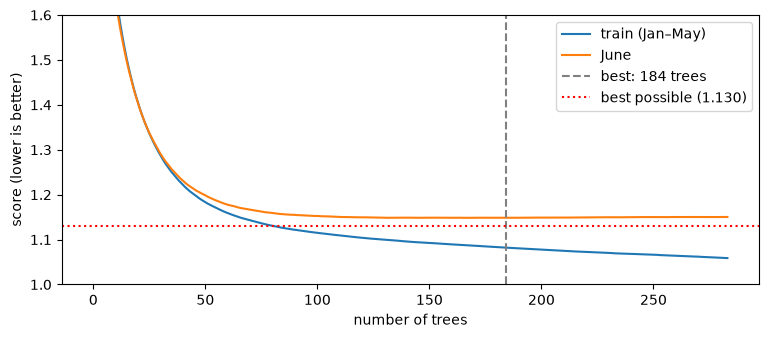

In [6]:
# The training curve: score after every tree, on train and on June
hist = model.evals_result_
fig, ax = plt.subplots(figsize=(9, 3.5))
ax.plot(hist["train"]["quantile"], label="train (Jan–May)")
ax.plot(hist["valid"]["quantile"], label="June")
ax.axvline(model.best_iteration_, color="grey", ls="--", label=f"best: {model.best_iteration_} trees")
ax.axhline(1.130, color="red", ls=":", label="best possible (1.130)")
ax.set_xlabel("number of trees"); ax.set_ylabel("score (lower is better)"); ax.set_ylim(1.0, 1.6); ax.legend()
plt.show()

**Questions**
1. After the best point, what happens to the training curve, and what happens to June? What is that called?
2. Why do we keep the number of trees where **June** was best, not where training was best?

*Answers:*
1. After the best point, the training score keeps improving, because each new tree fits the training visits a little more closely. June stops improving and starts getting worse. That is overfitting: the model begins memorising individual training visits instead of learning patterns that carry over to new ones. Early stopping is the fix. It stops adding trees once June stops improving.
2. the training score always keeps falling as you add trees, so "best on training" would just mean "use the most trees", which is the most overfit model. June is data the model never trained on, so its score estimates how the model will do on new visits. The number of trees where June was best is the point where the model has learned the real patterns but hasn't yet started memorising.

## Part 3 · One model per q, against your baselines

`fit_all` trains one model for each q and saves them to `outputs/models/`.

In [ ]:
models = fit_all(X_train, y_train, X_valid, y_valid)

In [10]:
# TODO(you): build the June leaderboard rows for LightGBM, one per q:
#   evaluate(y_valid, models[q].predict(X_valid), q, "LightGBM")
# Then put them together with your A5 baselines:  board = pd.concat([baselines, pd.DataFrame(rows)])
# Show method, q, pinball, coverage, booked_on_time, booked_idle_min, sorted by q then pinball.
# Finally save the LightGBM rows only:  pd.DataFrame(rows).to_csv(OUT / "lgbm_valid.csv", index=False)

if "models" not in globals():
	models = fit_all(X_train, y_train, X_valid, y_valid)

rows = [evaluate(y_valid, models[q].predict(X_valid), q, "LightGBM") for q in Q_CANDIDATES]
board = pd.concat([baselines, pd.DataFrame(rows)])
cols = ["method", "q", "pinball", "coverage", "booked_on_time", "booked_idle_min"]
display(board[cols].sort_values(["q", "pinball"]).reset_index(drop=True))
pd.DataFrame(rows).to_csv(OUT / "lgbm_valid.csv", index=False)

c:\Users\siddh\Documents\slot-prediction-model\.venv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
c:\Users\siddh\Documents\slot-prediction-model\.venv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
c:\Users\siddh\Documents\slot-prediction-model\.venv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


,method,q,pinball,coverage,booked_on_time,booked_idle_min
0,Oracle (floor),0.67,1.381000,0.677000,0.846000,4.230000
1,LightGBM,0.67,1.406770,0.663645,0.839529,4.180465
2,B3 doctor + visit type (backoff to B2),0.67,1.628000,0.673000,0.827000,4.474000
3,B2 department + visit type,0.67,1.700000,0.683000,0.803000,4.289000
4,B1 one number,0.67,2.635000,0.670000,0.688000,3.818000
5,B0 fixed 15,0.67,2.639000,0.688000,0.688000,3.818000
6,Oracle (floor),0.75,1.253000,0.754000,0.890000,5.095000
7,LightGBM,0.75,1.278578,0.742158,0.878332,4.946225
8,B3 doctor + visit type (backoff to B2),0.75,1.489000,0.759000,0.862000,5.261000
9,B2 department + visit type,0.75,1.556000,0.749000,0.866000,5.585000


**Questions**
1. For each q: how much of the gap between B3 and the best possible score does LightGBM close? (gap closed = (B3 − LightGBM) ÷ (B3 − best possible))
2. Is LightGBM's coverage close to q? Why does that matter (A1: coverage alone can be gamed, but it must still be right)?

*Answers:*
1. LightGBM closes about 90% of the gap at every q.
2. it is close to q: 0.664 vs 0.67, 0.742 vs 0.75, and 0.791 vs 0.80. Each is a little under, by 0.006 to 0.009.
- model could look good on one number while being systematically too short or too long. If coverage is close to q, then about q of visits fit in the booked slot, so the P80 really means "80% of visits finish in time", which is what the PO asked for. The score and coverage together show the model is both accurate and calibrated.

## Part 4 · Follow one visit through the trees

In [11]:
m = models[0.8]
i = int(np.flatnonzero((splits["valid"]["department"] == "Neurology").to_numpy()
                       & (splits["valid"]["visit_type"] == "new").to_numpy())[0])
row = X_valid.iloc[[i]]
display(row.T)
print("actual minutes:", round(float(y_valid.iloc[i]), 1))
for k in (1, 2, 3, 10, 50, 100, m.best_iteration_):
    prediction = np.asarray(m.predict(row, num_iteration=k)).item()
    print(f"after {k:>3} trees: P80 = {prediction:.2f}")

,42
department,Neurology
visit_type,new
doctor,Meera Pillai
clinic,Koramangala
age,41.0
age_missing,0
interpreter,0
teleconsult,0
prior_reports,2
weekday,1


actual minutes: 23.2
after   1 trees: P80 = 18.82
after   2 trees: P80 = 19.61
after   3 trees: P80 = 20.26
after  10 trees: P80 = 23.48
after  50 trees: P80 = 27.67
after 100 trees: P80 = 27.67
after 184 trees: P80 = 27.55


**Question:** the actual visit took less than the final P80. Is that a mistake? *(Hint: what does P80 promise about a single visit?)*

*Answer:*
A P80 says that about 80% of visits like this one finish at or before that time. It is not a prediction of this visit's exact length. So the actual visit finishing earlier than the P80 is the expected outcome for roughly 4 out of 5 visits. The model is wrong only if it ran over far more or far less often than that across many visits.

The cost of an early finish is the doctor sitting idle for the leftover minutes. That is the trade-off for a safe slot. The pinball loss charges for that idle time, but at a lower rate (1 − q) than for running late (q). That is why the model aims high on purpose.

## Part 5 · What did LightGBM rely on?

"Gain" = how much each column's questions lowered the score, added up over all trees, as a share of the total.

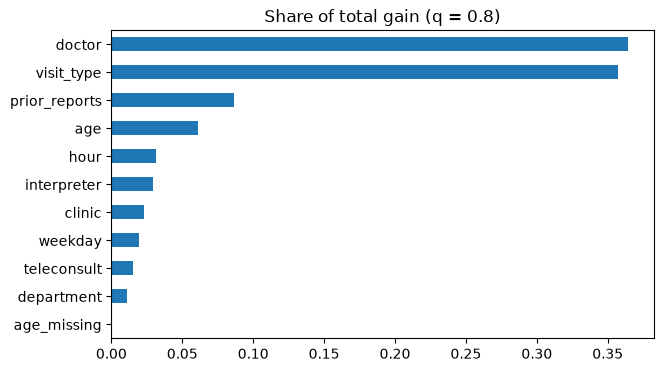

In [12]:
gain = pd.Series(m.booster_.feature_importance("gain"), index=m.booster_.feature_name())
(gain / gain.sum()).sort_values().plot.barh(figsize=(7, 4), title="Share of total gain (q = 0.8)")
plt.show()

**Question:** compare the top columns with how we built the simulator in A2 (`world.py`). Does LightGBM's ranking make sense? Which column ranks low, and why might that be?

*Answer:*
a visit's minutes are the base time for its visit type, plus reading time per prior report (capped at 8), plus interpreter time. That total is then multiplied by a pace that includes the doctor's speed. So visit type and doctor speed should dominate, then reports, then age (elderly and infant factors). The model found that structure from the data alone.

## Wrap-up (answer in `notes/A06-lightgbm.md` too, in your own words)

1. `min_child_samples = 30` is the same idea as which A5 rule?
2. Learning rate 0.05: a tree thinks a visit needs +10 minutes. How much does that tree actually move it?
3. Why stop adding trees when June stops improving?
4. In one or two sentences: how does boosting turn many rough trees into one good prediction?